# Contoso AI Gaming Companion: growth analysis

**Current scope:** audited preparation, four mandatory answers, feature-usage
and error associations, separate retention/conversion regressions, player groups,
and conversion journeys. Definitions were confirmed with the user before fitting.
Source-ledger and independent numerical checks support the results.

Source: [interview case](https://github.com/vejadu/InterviewCase-Gaming-PC-App).
This is public **synthetic example data**, not real customer evidence.
The downloaded statement and pinned commit are in `source/`.


## Problem and decision

The product team wants to identify growth and product improvement opportunities
for a PC app with an AI Game Optimizer, AI Game Coach (Chat), and AI Game Agent.
Mandatory questions cover new Free/Paid accounts, daily and weekly retention,
Free-to-Paid conversion, and Paid cancellations. Optional work examines feature
usage, errors, segments, and conversion timing.

**Population and window, as documented by the source (not yet validated):**
accounts starting March 3–7, 2025, followed for days 0–59; the statement describes
300 players and a last possible observation of May 5, 2025.
The grain is an observed active player-day; the independent unit is the player.
The source describes 60 players per start date.

The eventual assignment asks for a 10–15 minute leadership presentation,
a 10–15 minute technical discussion, and reproducible code. These are presentation
lengths, not an assumed analysis time budget. The notebook and checked evidence
also support the separately requested business and technical presentation.


## Definitions to preserve

- A missing player-day means no observed activity; it does not prove cancellation.
- Daily retention means active on a specific tenure day; weekly retention means
  active at least once in a defined tenure-week window. Use the day-0 cohort denominator.
- Plan and billing status are recorded at day end. A Free-to-Paid change appears
  on the upgrade day; recorded cancellation appears on the final Paid row.
  Day-0 plan is therefore an observed end-of-day starting classification;
  same-day signup/upgrade ordering cannot be recovered from daily snapshots.
- Feature totals include successes and errors. Daily limits are Optimizer/Coach/Agent:
  Free 100/10/5 and Paid 200/50/20. Limits differ, so raw usage comparisons need context.
- Usage and error relationships with outcomes will be descriptive associations.
  This synthetic, observational dataset does not identify causal product effects.


## Packages and local paths

Use **Python 3 (Contoso gaming case)**. These imports use existing project packages;
plotting packages are loaded for later use, but no charts are created here.
The path lookup supports launching from the project root or this case folder.


## How to read this notebook

Short cells state the question, show important definitions/formulas and display
the results. Repeated transformations, audit bookkeeping, model fitting, plots
and independent checks live in [case_helpers/](case_helpers/). Function calls
use explicit named inputs; helper docstrings describe their grain and assumptions.

Two small classes collect the run's records: `AuditTrail` owns quality/audit
ledgers and `RegressionCollection` owns fitted models and diagnostics. Data
calculations remain ordinary functions. [CODE_GUIDE.md](CODE_GUIDE.md) maps every
stage to its implementation. The four mandatory questions retain separate cells.


In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import platform
import sys

import numpy as np
import pandas as pd
from IPython.display import display

project_root = next(
    folder for folder in [Path.cwd(), *Path.cwd().parents]
    if (folder / "submission.json").is_file()
)
case_folder = project_root
data_path = project_root / "data" / "contoso_gaming_pc_app_output.csv"

In [2]:
environment = {
    "interpreter": sys.executable,
    "Python": platform.python_version(),
}
for package in ["pandas", "numpy", "matplotlib", "seaborn", "nbformat", "nbclient"]:
    environment[package] = importlib.metadata.version(package)
display(pd.Series(environment, name="Installed version or path"))

# Helpers contain the audited transformations and checks; see CODE_GUIDE.md.
sys.path.insert(0, str(case_folder))
from case_helpers import audit as audit_helpers
from case_helpers import preparation, validation, metrics, features, modeling, plotting, reporting
from case_helpers.audit import AuditTrail
from case_helpers.modeling import RegressionCollection
from collections import Counter, defaultdict
from IPython.display import Markdown

interpreter    <original-workstation>\miniforge3\envs\analytics-workb...
Python                                                   3.12.16
pandas                                                     3.1.0
numpy                                                      2.5.4
matplotlib                                                3.11.2
seaborn                                                   0.13.2
nbformat                                                  5.11.1
nbclient                                                  0.11.0
Name: Installed version or path, dtype: str

## Load the supplied data

Read the CSV without parsing dates, filtering, renaming, filling missing values,
or changing records. Pandas infers in-memory types; the source bytes stay unchanged.
The SHA-256 fingerprint records the exact input used. This is loading verification,
not a data-quality audit.


In [3]:
source_sha256 = hashlib.sha256(data_path.read_bytes()).hexdigest()
activity_raw = pd.read_csv(data_path)

print(f"Source: {data_path.relative_to(project_root)}")
print(f"SHA-256: {source_sha256}")
print(f"Loaded table: {activity_raw.shape[0]:,} rows × {activity_raw.shape[1]} columns")

Source: data\interview_question\contoso_gaming_pc_app_output.csv
SHA-256: 2efe179b13bd3dba1cbc6817e40395db4f544f76807f82001156c1d0da686067
Loaded table: 7,970 rows × 14 columns


## First look only

Show five source rows and inferred column types to become familiar with the file.
These rows are a preview, not a representative sample or a finding about players.
Dates remain as loaded until the later preparation stage.


In [4]:
with pd.option_context("display.max_columns", None, "display.max_colwidth", 40):
    display(activity_raw.head(5))

display(activity_raw.dtypes.rename("Loaded dtype").to_frame())

,date,userid,startdate,plan,Status,DayOfWeek,Weekend,DaysSinceStart,AI_AutoComplete_Success,AI_Chat_Success,AI_Agent_Success,AI_AutoComplete_Error,AI_Chat_Error,AI_Agent_Error
0,3/3/2025,11207503,3/3/2025,Paid,Active,Monday,False,0,37,4,2,2,0,0
1,3/3/2025,14003926,3/3/2025,Free,Active,Monday,False,0,5,6,2,0,0,0
2,3/3/2025,14017653,3/3/2025,Free,Active,Monday,False,0,5,2,3,0,0,2
3,3/3/2025,14453470,3/3/2025,Free,Active,Monday,False,0,9,8,2,1,0,0
4,3/3/2025,17463270,3/3/2025,Free,Active,Monday,False,0,29,3,1,1,0,0


,Loaded dtype
date,str
userid,int64
startdate,str
plan,str
Status,str
DayOfWeek,str
Weekend,bool
DaysSinceStart,int64
AI_AutoComplete_Success,int64
AI_Chat_Success,int64


## Analysis roadmap

1. **Validate the data contract.** Check player-day uniqueness, day-0 coverage,
   cohort dates, complete follow-up windows, nulls, date/tenure consistency,
   plan/status transitions, post-cancellation rows, nonnegative feature counts,
   and daily plan limits. Compare observed coverage with the source description.
2. **Prepare reproducibly.** Preserve `activity_raw` and source bytes. Parse dates
   into a separate table and produce a rule summary and row-level cleaning audit
   from the same code as any cleaning. If no cleaning is required, document the
   checks and that outcome. Reconcile rows and players before calculating metrics.
3. **Define the player cohort and metrics.** Build one row per day-0 player with
   observed initial plan. Count new accounts by that plan and cohort date.
   Define conversion as initially Free players with a subsequent Paid observation,
   divided by initially Free players; acknowledge day-0 same-day upgrades are unobservable.
   Count unique players with explicit Paid cancellation records. If reporting a
   cancellation proportion, define the denominator as players ever observed Paid,
   distinguish initially Paid from converters, and account for unequal Paid exposure.
4. **Calculate retention.** Use fixed day-0 cohort denominators, overall and by
   starting plan/cohort. Report exact-day activity separately from any-activity
   tenure weeks: week 1 = days 0–6, week 2 = 7–13, etc. Label days 56–59 as a
   partial final week. Verify follow-up availability before interpreting missing days.
5. **Explore journeys and associations after the mandatory metrics.** Examine
   upgrade timing, feature success/error rates (errors divided by attempts), and
   behavior segments. Define early exposure windows before later outcomes,
   address zero attempts and plan limits, and avoid using future activity to
   predict earlier outcomes. Repeated player-days are not independent observations.
   Predictive modeling is optional and only justified by a clear decision; if used,
   split by player before learned preprocessing and compare with a simple baseline.
6. **Verify and communicate.** Independently recalculate a headline count/rate
   from source-level records; reconcile denominators and boundary cases. Build
   checked charts and audience-specific recommendations with uncertainty and
   synthetic-data limitations. Create the requested deck only at that later stage.

**Current progress:** setup, audited preparation, mandatory questions and the
four additional goals are executed below. Early predictors and later outcomes
were confirmed with the user before fitting the association models.


## Cleaning contract and audit policy

We are preparing data for the four mandatory questions, without calculating their
aggregate answers. Keep every original column and add clearly named derived fields.
`source_row_id` is the CSV data-record number (1-based, excluding the header).

| Rule | Action and reason |
| --- | --- |
| Source lineage | Attach a stable source reference before preparation. |
| Contract checks | Validate keys, missingness, dates, day-0 coverage, transitions, cancellations and limits. Stop on conflicts rather than silently repair or exclude. |
| Dates and tenure | Parse explicit month/day/year dates into new fields; derive tenure and tenure week and compare supplied fields. |
| Activity flags and attempts | A source row is observed activity, even if all feature counts are zero. Explicit status alone identifies cancellation. Attempts = successes + errors. |
| Player roster | Anchor to day 0; derive first Paid and explicit cancellation dates, retaining nonconverters and noncancellers. |
| Calendar | Add days 0–59 per player; mark observed activity but leave absent plan/status/feature values missing. |
| Reconciliation | Check source values, joins, lineage and independent source-ledger calculations before export. |

`checks/transformation_summary.csv` records each applied rule and population
impact. `checks/cell_edits.csv` logs new field values and constructed calendar
rows, with keys and source references. Additions are distinguished from edits;
no original value is overwritten. Failed checks are saved before execution stops.


In [5]:
output_folder = case_folder / "outputs" / "cleaning"
checks_folder = output_folder / "checks"
checks_folder.mkdir(parents=True, exist_ok=True)

# Work on a copy and retain a permanent reference to every CSV data record.
original_columns = activity_raw.columns.tolist()
activity_clean = activity_raw.copy(deep=True)
activity_clean.insert(0, "source_row_id", np.arange(1, len(activity_clean) + 1))
audit = AuditTrail(activity_clean, checks_folder)
audit.record_rule("source_lineage", "Trace every source record without modifying inputs",
    activity_raw, activity_clean, len(activity_clean), activity_clean.userid.nunique(),
    "Added 1-based CSV data-record ID; no filtering or source-value edits")
audit.audit_added_fields(activity_clean, ["source_row_id"], "source_lineage", "activity_clean", "date")

# Parse dates explicitly while preserving the original text fields.
activity_clean["activity_date"] = pd.to_datetime(activity_clean.date, format="%m/%d/%Y", errors="coerce")
activity_clean["cohort_date"] = pd.to_datetime(activity_clean.startdate, format="%m/%d/%Y", errors="coerce")
activity_clean["tenure_day"] = (activity_clean.activity_date - activity_clean.cohort_date).dt.days

### Check dates, players and billing history

In [6]:
validation.check_dates_and_cohort(
    activity_clean=activity_clean,
    activity_raw=activity_raw,
    audit=audit,
)

feature_columns = validation.check_feature_limits(
    activity_clean=activity_clean,
    audit=audit,
    original_columns=original_columns,
)

cancellation_date_by_user = validation.check_billing_history(activity_clean=activity_clean, audit=audit)

### Review the saved quality checks

In [7]:
quality_checks = audit_helpers.save_quality_checks(audit=audit, checks_folder=checks_folder)

display(quality_checks)

All source-contract checks passed. No exclusions, imputations, or source-value corrections are required.


,check,description,violating_rows,violating_players,passed
0,required_fields_present,All supplied fields must be present,0.0,0.0,True
1,valid_dates,Dates parse under the stated US format,0.0,0.0,True
2,unique_player_day,One row per player per activity date,0.0,0.0,True
3,no_exact_duplicates,No identical input records,0.0,0.0,True
4,valid_plans,Only documented plans,0.0,0.0,True
5,valid_status,Only documented billing statuses,0.0,0.0,True
6,cohort_dates,Account creation dates are in assignment window,0.0,0.0,True
7,stable_cohort,Each player has one cohort date,0.0,0.0,True
8,tenure_matches_source,Calendar date difference equals supplied tenure,0.0,0.0,True
9,tenure_in_window,Only days 0 through 59,0.0,0.0,True


## Prepare the observed activity table

The contract checks above determine whether preparation can proceed. The next
steps add typed dates, verified tenure, week labels, observed-activity and explicit
cancellation flags, and attempt totals. All original source columns remain intact.
Week 1 covers days 0–6; week 9 covers days 56–59 and is explicitly partial.
Observed activity is defined by the presence of a source row, not feature usage.


### Add analysis fields with an audit trail

In [8]:
activity_clean, date_fields, derived_fields = preparation.derive_activity_fields(
    activity_clean=activity_clean,
    activity_raw=activity_raw,
    audit=audit,
)

display(activity_clean.head(5))

,source_row_id,date,userid,startdate,plan,Status,DayOfWeek,Weekend,DaysSinceStart,AI_AutoComplete_Success,...,activity_date,cohort_date,tenure_day,tenure_week,is_partial_week,observed_activity,explicit_cancellation,optimizer_attempts,coach_attempts,agent_attempts
0,61,3/4/2025,10213838,3/4/2025,Free,Active,Tuesday,False,0,5,...,2025-03-04,2025-03-04,0,1,False,True,False,5,5,0
1,451,3/7/2025,10213838,3/4/2025,Free,Active,Friday,False,3,7,...,2025-03-07,2025-03-04,3,1,False,True,False,7,7,0
2,1066,3/10/2025,10213838,3/4/2025,Free,Active,Monday,False,6,5,...,2025-03-10,2025-03-04,6,1,False,True,False,5,7,1
3,1398,3/12/2025,10213838,3/4/2025,Free,Active,Wednesday,False,8,5,...,2025-03-12,2025-03-04,8,2,False,True,False,6,4,0
4,2072,3/16/2025,10213838,3/4/2025,Free,Active,Sunday,True,12,4,...,2025-03-16,2025-03-04,12,2,False,True,False,4,4,0


## Prepare the player table

Anchor the roster on each player's validated day-0 record. Dates for first Paid
observation and explicit cancellation come from all that player's source records;
the audit lineage maps those records to each player. An absent event date means
**not observed within the window**, not that the event can never occur.

`converted_from_initial_free` applies only to initially Free players. Plan on day 0
is an end-of-day observation; same-day signup/upgrade ordering remains unobservable.
The follow-up cutoff is the source statement's May 5 end date, not last activity.
Full 60-day data availability relies on the source's complete synthetic-file
declaration; coverage checks cannot independently prove telemetry completeness.


### One record per player

In [9]:
player_summary, player_fields = preparation.build_player_table(
    activity_clean=activity_clean,
    audit=audit,
    cancellation_date_by_user=cancellation_date_by_user,
    checks_folder=checks_folder,
)

display(player_summary[["userid", "cohort_date", "initial_plan", "window_end_date"]].head())

Prepared 300 player records; event flags are saved without aggregate outcome counts.


,userid,cohort_date,initial_plan,window_end_date
0,10213838,2025-03-04,Free,2025-05-02
1,10439750,2025-03-06,Paid,2025-05-04
2,10453161,2025-03-05,Free,2025-05-03
3,10517792,2025-03-06,Free,2025-05-04
4,10522638,2025-03-07,Free,2025-05-05


## Construct a complete retention calendar

Create 60 rows per day-0 player, including after explicit cancellation, to preserve
the original retention denominator. `observed_activity=False` means no source
activity row. It does not infer billing status or cancellation. For added rows,
plan, Status and feature counts stay missing; no forward filling is performed.
The row-level ledger logs every added calendar row, while `source_row_id` links
every observed row back to the file. This calendar is a new output table, not an
expansion of the cleaned observed-activity table.


### Build the complete retention calendar

In [10]:
player_day_calendar, added_calendar_rows = preparation.build_retention_calendar(
    activity_clean=activity_clean,
    audit=audit,
    feature_columns=feature_columns,
    player_summary=player_summary,
)

In [11]:
week_windows = pd.DataFrame({"tenure_week": np.arange(1, 10)})
week_windows["start_day_inclusive"] = (week_windows.tenure_week - 1) * 7
week_windows["end_day_inclusive"] = (week_windows.start_day_inclusive + 6).clip(upper=59)
week_windows["days_in_window"] = week_windows.end_day_inclusive - week_windows.start_day_inclusive + 1
week_windows["is_partial_week"] = week_windows.days_in_window.lt(7)
display(week_windows)
print(f"Prepared {len(player_day_calendar):,} player-days; {len(added_calendar_rows):,} constructed rows clearly labeled.")

,tenure_week,start_day_inclusive,end_day_inclusive,days_in_window,is_partial_week
0,1,0,6,7,False
1,2,7,13,7,False
2,3,14,20,7,False
3,4,21,27,7,False
4,5,28,34,7,False
5,6,35,41,7,False
6,7,42,48,7,False
7,8,49,55,7,False
8,9,56,59,4,True


Prepared 18,000 player-days; 10,030 constructed rows clearly labeled.


## Reconcile and independently verify the preparation

Check source preservation and audit completeness, then independently read the CSV
using Python's standard-library reader. That separate path reconstructs each
player's day-0 plan, first Paid date, cancellation date, and activity keys, and
compares them with the prepared outputs. This verifies preparation without
reporting the four business answers. Assertions stop exports if a check fails.


### Reconcile source values and retention denominators

In [12]:
validation.verify_preservation_and_calendar(
    activity_clean=activity_clean,
    activity_raw=activity_raw,
    added_calendar_rows=added_calendar_rows,
    audit=audit,
    data_path=data_path,
    feature_columns=feature_columns,
    original_columns=original_columns,
    player_day_calendar=player_day_calendar,
    player_summary=player_summary,
    source_sha256=source_sha256,
)

### Independently check each player's event dates

In [13]:
source_ledger, source_keys = validation.read_player_ledger(data_path=data_path)

validation.verify_player_events(
    audit=audit,
    player_day_calendar=player_day_calendar,
    player_summary=player_summary,
    source_keys=source_keys,
    source_ledger=source_ledger,
)

### Reconcile the additions log

In [14]:
cell_edits, transformation_summary = audit_helpers.reconcile_added_fields(
    activity_clean=activity_clean,
    added_calendar_rows=added_calendar_rows,
    audit=audit,
    checks_folder=checks_folder,
    date_fields=date_fields,
    derived_fields=derived_fields,
    player_fields=player_fields,
    player_summary=player_summary,
)

display(transformation_summary)
display(pd.DataFrame(audit.validation_results))

,rule,reason,affected_rows,affected_players,rows_before,rows_after,players_before,players_after,cohort_denominator_change,detail
0,source_lineage,Trace every source record without modifying in...,7970,300,7970,7970,300,300,0,Added 1-based CSV data-record ID; no filtering...
1,typed_dates_and_tenure,Add analysis-safe dates and verify tenure with...,7970,300,7970,7970,300,300,0,"Explicit %m/%d/%Y parsing; original date, star..."
2,activity_derivations,Prepare daily/weekly activity and feature deno...,7970,300,7970,7970,300,300,0,Source-row presence establishes activity; no a...
3,sort_activity,Order records for reproducible within-player t...,7970,300,7970,7970,300,300,0,Sorted by userid and activity_date; source_row...
4,player_roster_and_events,Prepare stable cohort denominators and event d...,7970,300,7970,300,300,300,0,Observed player-day -> player; day0/event join...
5,retention_calendar,Preserve full day0 cohort for each tenure day ...,10030,300,7970,18000,300,300,0,Player x 60 tenure days; observed matches=7970...


,check,passed
0,all_original_values_preserved,True
1,input_sha256_unchanged,True
2,activity_row_count_preserved,True
3,player_population_preserved,True
4,calendar_one_row_per_player_day,True
5,calendar_60_days_per_player,True
6,all_observed_rows_match_calendar_once,True
7,absent_billing_and_counts_remain_unknown,True
8,all_day0_players_present_in_calendar,True
9,feature_totals_preserved,True


## Save prepared data and the audit trail

Parquet preserves dates, booleans and nullable integers. The CSV audit files remain
readable without Python. Reload checks verify that the saved tables match the
in-memory data. The player and calendar outputs are ready for the four mandatory
questions, subject to the source's coverage declaration and day-0 plan limitation.
No aggregate retention, conversion, plan split, or cancellation results are produced.


### Save the prepared data

In [15]:
preparation.save_prepared_tables(
    activity_clean=activity_clean,
    audit=audit,
    output_folder=output_folder,
    player_day_calendar=player_day_calendar,
    player_summary=player_summary,
    week_windows=week_windows,
)

### Record dimensions, checks and reproduction details

In [16]:
manifest = reporting.save_preparation_manifest(
    activity_clean=activity_clean,
    activity_raw=activity_raw,
    added_calendar_rows=added_calendar_rows,
    audit=audit,
    cell_edits=cell_edits,
    checks_folder=checks_folder,
    data_path=data_path,
    environment=environment,
    output_folder=output_folder,
    player_day_calendar=player_day_calendar,
    player_summary=player_summary,
    project_root=project_root,
    quality_checks=quality_checks,
    source_sha256=source_sha256,
)

reporting.write_preparation_record(
    case_folder=case_folder,
    manifest=manifest,
    source_sha256=source_sha256,
)

{
  "raw_rows": 7970,
  "clean_activity_rows": 7970,
  "players": 300,
  "calendar_rows": 18000,
  "added_calendar_rows": 10030,
  "source_value_edits": 0,
  "excluded_source_rows": 0,
  "quality_checks_passed": 29,
  "reconciliation_checks_passed": 20,
  "audit_entries": 102800
}


## Preparation outcome and handoff

The executed checks and manifest above reconcile the complete input population
to the prepared tables and audit trail. No defects required source-value edits,
exclusions or imputation. The additions are typed/derived fields, one-row-per-player
summaries, and an explicitly labeled retention calendar.

| Mandatory question | Ready-to-use table and fields | Denominator or boundary |
| --- | --- | --- |
| New Free/Paid accounts | `player_summary`: `userid`, `cohort_date`, `initial_plan` | One validated day-0 player; observed end-of-day plan |
| Daily/weekly retention | `player_day_calendar`: `userid`, `tenure_day`, `tenure_week`, `observed_activity`, `is_partial_week` | Original day-0 cohort; week 9 is partial; source-declared full coverage |
| Free-to-Paid conversion | `player_summary`: `initially_free`, `converted_from_initial_free`, `conversion_date`, `conversion_tenure_day` | All initially Free players, including nonconverters |
| Paid cancellations | `player_summary`: `ever_observed_paid`, `explicit_cancellation_observed`, `cancellation_date`, `initial_plan` | Count distinct explicit cancellation events; any rate requires an explicit Paid denominator |

Reload with `pd.read_parquet(output_folder / "player_summary.parquet")` (and
similarly for `activity_clean` or `player_day_calendar`). Parquet retains field
types. Original field definitions remain in `source/README.md`; new-field
definitions and output paths are in the case `README.md`.

**Stopping point:** preparation is complete. Aggregate new-account counts by
plan, retention, conversion, cancellation answers, charts and modeling remain pending.


# Mandatory questions

**Readiness: proceed with documented limitations.** The 29 data-contract and 20
preparation-reconciliation checks above passed. The calculations below reload
the saved cleaned tables. We describe the entire supplied synthetic cohort;
these are observed counts and proportions, not population forecasts or causal
effects, so sampling confidence intervals are not added.

Full follow-up relies on the pinned source's complete-data declaration. Starting
plan is observed at day-end on day 0; same-day signup/upgrade ordering cannot be
recovered. Every question has its own code cell, followed by a verification cell.


## Question 1 — How many new Free and Paid accounts were created March 3–7?

Use `player_summary`: one row per day-0 player. Count by **initial plan**, rather
than current/last plan, so later upgrades do not change the starting-plan counts.
Show the full enrollment window and each start date as a reconciliation.


In [17]:
# Reload the saved player table so these answers use the cleaned outputs.
players = pd.read_parquet(output_folder / "player_summary.parquet")
assert players.userid.is_unique, "Player summary must contain exactly one row per player."
assert players.cohort_date.between("2025-03-03", "2025-03-07").all()
assert players.full_60_day_window_available.all(), "Review incomplete follow-up before answering."

results_folder = case_folder / "outputs" / "mandatory_questions"
tables_folder = results_folder / "tables"
tables_folder.mkdir(parents=True, exist_ok=True)

new_accounts = players.groupby("initial_plan").size().reindex(["Free", "Paid"], fill_value=0)
new_accounts = new_accounts.rename("new_players").rename_axis("initial_plan").reset_index()
new_accounts_by_date = pd.crosstab(players.cohort_date, players.initial_plan)
new_accounts_by_date = new_accounts_by_date.reindex(columns=["Free", "Paid"], fill_value=0)
new_accounts_by_date["Total"] = new_accounts_by_date.sum(axis=1)
assert new_accounts.new_players.sum() == len(players), "Starting-plan counts must cover the entire cohort."

display(new_accounts)
display(new_accounts_by_date)
initial_counts = new_accounts.set_index("initial_plan").new_players
print(f"Answer: {initial_counts['Free']:,} initially Free and {initial_counts['Paid']:,} initially Paid players; {len(players):,} total.")
print("These are observed day-0 end-of-day plans, not separately logged signup-plan events.")
new_accounts.to_csv(tables_folder / "q1_new_accounts.csv", index=False)
new_accounts_by_date.to_csv(tables_folder / "q1_new_accounts_by_date.csv")

,initial_plan,new_players
0,Free,232
1,Paid,68


initial_plan,Free,Paid,Total
cohort_date,,,
2025-03-03,44,16,60
2025-03-04,45,15,60
2025-03-05,48,12,60
2025-03-06,47,13,60
2025-03-07,48,12,60


Answer: 232 initially Free and 68 initially Paid players; 300 total.
These are observed day-0 end-of-day plans, not separately logged signup-plan events.


## Question 2 — How many players return in subsequent days and weeks? What is retention?

Use `player_day_calendar`. **Daily retention** = distinct players active on that
exact tenure day / all day-0 players. **Weekly retention** = distinct players
active at least once in that tenure-week window / all day-0 players. A player
active on several days counts once in their week's numerator.

The denominator stays fixed, including after cancellation or nonreturn. These
are tenure days/weeks since each player's start date, not calendar weeks.
Week 1 (days 0–6) includes signup and is 100% by construction; week 9 (days 56–59)
is partial. Missing source rows mean no observed activity, not cancellation.


In [18]:
calendar = pd.read_parquet(output_folder / "player_day_calendar.parquet")
assert not calendar.duplicated(["userid", "tenure_day"]).any()
assert set(calendar.userid) == set(players.userid)
assert calendar.groupby("userid").size().eq(60).all()
assert calendar.full_60_day_window_available.all()
cohort_players = len(players)

daily_retention, weekly_retention = metrics.retention_tables(
    calendar=calendar,
    cohort_players=cohort_players,
    output_folder=output_folder,
)

print("Daily retention — active on that exact tenure day:")
with pd.option_context("display.max_rows", 60):
    display(daily_retention.style.format({"retention_pct": "{:.1f}%"}))
print("Weekly retention — active at least once in the indicated tenure-day window:")
display(weekly_retention.style.format({"retention_pct": "{:.1f}%"}))
for day in [1, 7, 14, 30, 59]:
    result = daily_retention.loc[daily_retention.tenure_day.eq(day)].iloc[0]
    print(f"Day {day}: {int(result.active_players):,}/{cohort_players:,} active ({result.retention_pct:.1f}%).")
print("Day 7 retention is exact-day activity; week 2 retention covers any activity on days 7–13.")
print("Week 1 includes day 0. The partial final week has fewer chances to observe a return than a full week.")
daily_retention.to_csv(tables_folder / "q2_daily_retention.csv", index=False)
weekly_retention.to_csv(tables_folder / "q2_weekly_retention.csv", index=False)

Daily retention — active on that exact tenure day:


,tenure_day,active_players,day0_cohort_players,retention_pct
0,0,300,300,100.0%
1,1,182,300,60.7%
2,2,188,300,62.7%
3,3,182,300,60.7%
4,4,192,300,64.0%
5,5,192,300,64.0%
6,6,176,300,58.7%
7,7,161,300,53.7%
8,8,159,300,53.0%
9,9,167,300,55.7%


Weekly retention — active at least once in the indicated tenure-day window:


,tenure_week,start_day_inclusive,end_day_inclusive,days_in_window,is_partial_week,active_players,day0_cohort_players,retention_pct
0,1,0,6,7,False,300,300,100.0%
1,2,7,13,7,False,260,300,86.7%
2,3,14,20,7,False,226,300,75.3%
3,4,21,27,7,False,212,300,70.7%
4,5,28,34,7,False,180,300,60.0%
5,6,35,41,7,False,161,300,53.7%
6,7,42,48,7,False,150,300,50.0%
7,8,49,55,7,False,137,300,45.7%
8,9,56,59,4,True,123,300,41.0%


Day 1: 182/300 active (60.7%).
Day 7: 161/300 active (53.7%).
Day 14: 149/300 active (49.7%).
Day 30: 121/300 active (40.3%).
Day 59: 87/300 active (29.0%).
Day 7 retention is exact-day activity; week 2 retention covers any activity on days 7–13.
Week 1 includes day 0. The partial final week has fewer chances to observe a return than a full week.


## Question 3 — How many Free players upgraded to Paid? What is conversion?

Use `player_summary`. The denominator is **all initially Free players**, including
those who never return. The numerator is initially Free players subsequently
observed Paid within days 0–59. Initially Paid players are excluded from both.
This measures observed conversion from the day-0 Free state; same-day signup
and upgrade events before that snapshot are not recoverable.


In [19]:
initially_free_players = players.loc[players.initially_free].copy()
free_players_count = len(initially_free_players)
converted_players_count = int(initially_free_players.converted_from_initial_free.sum())
conversion_pct = 100 * converted_players_count / free_players_count if free_players_count else np.nan

conversion_summary = pd.DataFrame([{
    "initially_free_players": free_players_count,
    "converted_to_paid_players": converted_players_count,
    "not_observed_converted_players": free_players_count - converted_players_count,
    "conversion_pct": conversion_pct,
    "tenure_window": "days 0–59; conversion after observed day-0 Free state",
}])
display(conversion_summary.style.format({"conversion_pct": "{:.1f}%"}))
print(f"Answer: {converted_players_count:,} of {free_players_count:,} initially Free players upgraded; conversion = {conversion_pct:.1f}%.")
print("The remaining players were not observed converting within this window; this does not mean they can never convert.")
conversion_summary.to_csv(tables_folder / "q3_free_to_paid_conversion.csv", index=False)

,initially_free_players,converted_to_paid_players,not_observed_converted_players,conversion_pct,tenure_window
0,232,33,199,14.2%,days 0–59; conversion after observed day-0 Free state


Answer: 33 of 232 initially Free players upgraded; conversion = 14.2%.
The remaining players were not observed converting within this window; this does not mean they can never convert.


## Question 4 — How many Paid players cancelled?

Use `player_summary` and count players with **explicit cancellation records**.
Include both initially Paid players and initially Free players who converted.
Show those groups separately to make the count auditable. The question asks for
a count; these groups have different Paid exposure lengths, so their counts
should not be interpreted as comparable cancellation risks or monthly churn rates.


In [20]:
paid_players = players.loc[players.ever_observed_paid].copy()
assert not players.loc[players.explicit_cancellation_observed, "ever_observed_paid"].eq(False).any()
cancelled_players_count = int(paid_players.explicit_cancellation_observed.sum())

cancellation_summary = pd.DataFrame([{
    "ever_observed_paid_players": len(paid_players),
    "explicitly_cancelled_players": cancelled_players_count,
    "no_recorded_cancellation_players": len(paid_players) - cancelled_players_count,
}])
cancellations_by_starting_plan = paid_players.groupby("initial_plan", as_index=False).agg(
    ever_observed_paid_players=("userid", "size"),
    explicitly_cancelled_players=("explicit_cancellation_observed", "sum"),
)
assert cancellations_by_starting_plan.explicitly_cancelled_players.sum() == cancelled_players_count
display(cancellation_summary)
display(cancellations_by_starting_plan)
print(f"Answer: {cancelled_players_count:,} distinct Paid players have explicit cancellation records within days 0–59.")
print("Paid players include both day-0 Paid accounts and subsequent Free-to-Paid converters.")
print("No recorded cancellation is not proof of current subscription status after the file ends; missing activity alone is not cancellation.")
cancellation_summary.to_csv(tables_folder / "q4_paid_cancellations.csv", index=False)
cancellations_by_starting_plan.to_csv(tables_folder / "q4_cancellations_by_starting_plan.csv", index=False)

,ever_observed_paid_players,explicitly_cancelled_players,no_recorded_cancellation_players
0,101,16,85


,initial_plan,ever_observed_paid_players,explicitly_cancelled_players
0,Free,33,3
1,Paid,68,13


Answer: 16 distinct Paid players have explicit cancellation records within days 0–59.
Paid players include both day-0 Paid accounts and subsequent Free-to-Paid converters.
No recorded cancellation is not proof of current subscription status after the file ends; missing activity alone is not cancellation.


## Independent verification and saved answer summary

Reread the original CSV with `csv.DictReader`. Independently count day-0 plan
memberships, sets of active players per day/week, initially Free players later
observed Paid, and explicitly cancelled players. Compare all answers and every
retention numerator/percentage with the cleaned-table route. No new cleaning
is applied. Recheck that the source fingerprint is unchanged.


### Check all four answers through an independent CSV calculation

In [21]:
answer_checks = validation.verify_mandatory_answers(
    cancelled_players_count=cancelled_players_count,
    conversion_pct=conversion_pct,
    converted_players_count=converted_players_count,
    daily_retention=daily_retention,
    data_path=data_path,
    free_players_count=free_players_count,
    initial_counts=initial_counts,
    paid_players=paid_players,
    results_folder=results_folder,
    source_sha256=source_sha256,
    weekly_retention=weekly_retention,
)

display(pd.DataFrame([{"check": name, "passed": passed} for name, passed in answer_checks.items()]))

,check,passed
0,q1_starting_plan_counts,True
1,q2_all_daily_counts,True
2,q2_all_weekly_counts,True
3,q2_fixed_day0_denominators,True
4,q2_all_daily_percentages,True
5,q2_all_weekly_percentages,True
6,q3_conversion_count_and_denominator,True
7,q3_conversion_percentage,True
8,q4_explicit_cancellations,True
9,q4_paid_population,True


### Save the mandatory-answer summary

In [22]:
answer_brief = reporting.write_mandatory_answers(
    answer_checks=answer_checks,
    cancelled_players_count=cancelled_players_count,
    case_folder=case_folder,
    cohort_players=cohort_players,
    conversion_pct=conversion_pct,
    converted_players_count=converted_players_count,
    daily_retention=daily_retention,
    free_players_count=free_players_count,
    initial_counts=initial_counts,
    paid_players=paid_players,
    results_folder=results_folder,
    weekly_retention=weekly_retention,
)

display(Markdown(answer_brief))

# Mandatory-question answers

    Synthetic Contoso cohort starting March 3–7, 2025; tenure days 0–59.

    1. **New accounts:** 232 initially Free and 68 initially Paid, 300 total. Initial plan is the observed day-0 end-of-day state.
    2. **Retention:** day 59 has 87/300 active players (29.0%). Last full tenure week (days 49–55) has 137/300 active at least once (45.7%). Partial week 9 (days 56–59) has 123/300 (41.0%). Full daily and weekly tables are in `tables/q2_daily_retention.csv` and `tables/q2_weekly_retention.csv`; all use the original day-0 denominator. Week 1 includes signup and is 100% by construction.
    3. **Free-to-Paid:** 33/232 initially Free players converted (14.2%). Same-day signup and upgrade ordering is not observable.
    4. **Paid cancellations:** 16 distinct players have explicit cancellation records; 101 players were ever observed Paid, including converters. Counts do not standardize unequal Paid exposure.

    All 11 independent answer checks passed against the original CSV.
    Missing activity is not cancellation. Full coverage relies on the source's
    complete synthetic-data declaration. These descriptive results do not establish
    causal product effects. No feature-usage analysis, charts or presentation created.

    Reproduce by restarting the project kernel and running `analysis.ipynb`, or run
    `python exercises/interview_question/create_notebook.py` in the activated project
    environment. Full notebook code is exported to `analysis.py`; `prepare_data.py`
    remains the preparation-only export. Environment and input hash are recorded in
    `../cleaning/checks/preparation_manifest.json`.
    

# Additional goals: feature associations, segments and conversion journeys

**User-confirmed definitions:** predictors are measured during days 0–6.
Retention means any observed activity during days 28–34. Conversion means a
first Paid observation during days 7–59 among initially Free players not yet
converted by day 6. One player is one independent observation for these models.

The plan below is fixed before inspecting feature/outcome associations.
These are exploratory associations in synthetic data, not causal effects or
validated forecasts. No feature or segment is selected because of its outcome.

1. Report rank correlations, with permutation p-values and multiplicity adjustment.
2. Fit separate retention and conversion logistic regressions using all three
   first-week feature volumes, active days, and initial Paid status for retention.
3. Fit one error-rate model per feature/outcome, controlling for that feature's
   volume, active days, and initial Paid status where relevant. Rates remain
   undefined when attempts are zero; exclusions are reported rather than imputed.
4. Compare prespecified weekend/weekday and plan-limit-normalized feature
   preference groups, then fit adjusted group models.
5. Report conversion risk sets, event timing, pre-upgrade journeys and a discrete
   daily conversion-hazard regression with player-clustered uncertainty.

Intervals are pointwise model-based 95% intervals. Benjamini–Hochberg q-values
summarize exploratory multiple comparisons, separately for correlations and
the 12 primary feature slopes. The 33 conversions limit precision and model
complexity. We also check simpler specifications and first-week plan differences.

In [23]:
association_folder = case_folder / "outputs" / "additional_analysis"
association_tables = association_folder / "tables"
association_checks = association_folder / "checks"
association_figures = association_folder / "figures"
for folder in [association_tables, association_checks, association_figures]:
    folder.mkdir(parents=True, exist_ok=True)

analysis_plan = reporting.save_association_plan(association_checks=association_checks)

activity = pd.read_parquet(output_folder / "activity_clean.parquet")
roster = pd.read_parquet(output_folder / "player_summary.parquet")
calendar = pd.read_parquet(output_folder / "player_day_calendar.parquet")

### Aggregate first-week predictors and define later outcomes

In [24]:
early_activity, early_features, feature_map = features.first_week_features(activity=activity)

model_players, conversion_players, samples, sample_summary = features.define_later_outcomes(
    association_tables=association_tables,
    calendar=calendar,
    early_features=early_features,
    roster=roster,
)

display(sample_summary)

,outcome,players,events,nonevents
0,retention,300,180,120
1,conversion,232,33,199


### Save feature lineage and model eligibility

In [25]:
feature_audit = audit_helpers.save_first_week_lineage(
    association_checks=association_checks,
    calendar=calendar,
    conversion_players=conversion_players,
    early_activity=early_activity,
    early_features=early_features,
    feature_map=feature_map,
    model_players=model_players,
)

## Feature profile and correlation analysis

Totals refer to the full seven-calendar-day window. A player with fewer active
days has fewer observed attempts, which motivates adjustment for active days.
Zero attempts give a genuine zero volume but an undefined error rate.
Rank correlation with a binary outcome compares predictor ranks in outcome groups.
Permuting outcome labels gives an exploratory unadjusted test of independence.
It does not adjust for starting plan, general engagement, or other features.

In [26]:
profile_fields = ["active_days"] + [f"{feature}_{suffix}" for feature in feature_map for suffix in ["attempts", "errors", "error_rate"]]
feature_profile = model_players[profile_fields].describe().T
feature_profile["missing_players"] = model_players[profile_fields].isna().sum()
feature_profile.to_csv(association_tables / "first_week_feature_profile.csv")
display(feature_profile)

,count,mean,std,min,25%,50%,75%,max,missing_players
active_days,300.0,4.706667,1.631819,1.0,3.000000,5.000000,6.000000,7.000000,0
optimizer_attempts,300.0,59.303333,56.363174,4.0,24.000000,41.000000,72.000000,350.000000,0
optimizer_errors,300.0,2.930000,3.392659,0.0,1.000000,2.000000,4.000000,20.000000,0
optimizer_error_rate,300.0,0.047929,0.041534,0.0,0.021623,0.044499,0.066667,0.285714,0
coach_attempts,300.0,21.586667,17.529216,0.0,9.000000,16.000000,30.000000,80.000000,0
coach_errors,300.0,1.000000,1.269661,0.0,0.000000,1.000000,2.000000,6.000000,0
coach_error_rate,298.0,0.045450,0.068136,0.0,0.000000,0.025479,0.067514,0.500000,2
agent_attempts,300.0,9.080000,8.158152,0.0,3.000000,7.000000,12.250000,41.000000,0
agent_errors,300.0,0.663333,1.067922,0.0,0.000000,0.000000,1.000000,7.000000,0
agent_error_rate,289.0,0.057004,0.087718,0.0,0.000000,0.000000,0.095238,0.500000,11


In [27]:
correlations = features.correlate_features_and_outcomes(
    association_tables=association_tables,
    feature_map=feature_map,
    samples=samples,
)

display(correlations.round(4))

,outcome,feature,measurement,players,excluded_zero_attempts,spearman_rho,permutation_p,bh_q
0,retention,optimizer,attempts,300,0,0.2582,0.0002,0.0012
1,retention,optimizer,errors,300,0,0.1932,0.0008,0.0029
2,retention,optimizer,error_rate,300,0,0.0770,0.1826,0.2191
3,retention,coach,attempts,300,0,0.3124,0.0002,0.0012
4,retention,coach,errors,300,0,0.1338,0.0206,0.0371
5,retention,coach,error_rate,298,2,0.0465,0.4312,0.4312
6,retention,agent,attempts,300,0,0.3073,0.0002,0.0012
7,retention,agent,errors,300,0,0.2169,0.0004,0.0018
8,retention,agent,error_rate,289,11,0.1571,0.0092,0.0184
9,conversion,optimizer,attempts,232,0,0.1870,0.0032,0.0082


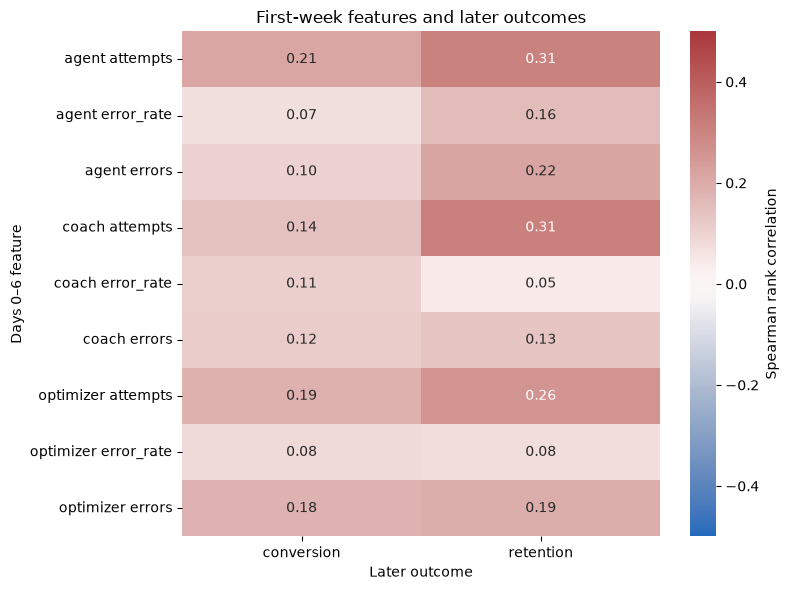

Error counts can reflect volume rather than reliability. The error-rate regressions below control for attempts.


In [28]:
plotting.correlation_heatmap(
    association_figures=association_figures,
    association_tables=association_tables,
    correlations=correlations,
)

## Logistic regression method and diagnostics

Logistic regression models the log odds of a binary outcome. We report odds
ratios (ORs) and 95% intervals, not percentage-point effects. A volume coefficient
is per doubling of **1 + first-week attempts**. Error-rate coefficients are per
10 percentage points. OR > 1 means a positive association, conditional on controls.

Primary usage formulas are visible in the next cell. HC1 standard errors treat
players as independent. Error models include one feature at a time to keep
complexity manageable and explicitly control its attempt volume. These models
do not mutually adjust all three error rates. Only 33 conversion events means
wide intervals and unstable estimates are possible. No held-out prediction
claims are made. We check convergence, warnings, rank, condition number and VIF.
See [statsmodels GLM documentation](https://www.statsmodels.org/stable/generated/statsmodels.genmod.generalized_linear_model.GLM.html).

In [29]:
from statsmodels.stats.multitest import multipletests

# The collection records each fit and its diagnostics; formulas remain visible.
models = RegressionCollection()
usage_terms = "log2_optimizer + log2_coach + log2_agent + active_days"
retention_formula = "retained ~ " + usage_terms + " + initial_paid"
conversion_formula = "later_conversion ~ " + usage_terms
print("Retention model:", retention_formula)
print("Conversion model:", conversion_formula)

Retention model: retained ~ log2_optimizer + log2_coach + log2_agent + active_days + initial_paid
Conversion model: later_conversion ~ log2_optimizer + log2_coach + log2_agent + active_days


## Goal 1 — Feature usage versus retention and conversion

The retention model uses all 300 players and controls initial plan. The
conversion model uses only eligible initially Free players. Active days is
included to distinguish feature volume from general first-week engagement.
All three feature volumes are included together. Adjustment describes
associations conditional on these variables and does not identify causal effects.

In [30]:
retention_usage = models.fit("retention_usage", model_players, retention_formula)
conversion_usage = models.fit("conversion_usage", conversion_players, conversion_formula)
primary_usage = pd.concat([retention_usage, conversion_usage], ignore_index=True)
primary_usage = primary_usage.loc[primary_usage.term.isin(["log2_optimizer", "log2_coach", "log2_agent"])].copy()
display(primary_usage[["model", "term", "odds_ratio", "ci_low", "ci_high", "p_value"]].round(4))
primary_usage.to_csv(association_tables / "usage_regression_coefficients.csv", index=False)

,model,term,odds_ratio,ci_low,ci_high,p_value
1,retention_usage,log2_optimizer,1.2914,0.9451,1.7646,0.1083
2,retention_usage,log2_coach,1.5139,1.1124,2.0604,0.0084
3,retention_usage,log2_agent,1.5184,1.1491,2.0062,0.0033
7,conversion_usage,log2_optimizer,1.8439,1.1869,2.8646,0.0065
8,conversion_usage,log2_coach,1.6746,1.0281,2.7277,0.0383
9,conversion_usage,log2_agent,2.0906,1.1271,3.8778,0.0193


### Compare simpler usage specifications

In [31]:
modeling.fit_usage_sensitivities(
    feature_map=feature_map,
    models=models,
    samples=samples,
    usage_terms=usage_terms,
)

## Goal 2 — Feature errors versus retention and conversion

For each feature, error rate = first-week errors / first-week attempts.
Players with zero attempts are excluded only from that feature's error model;
zero errors among positive attempts remain valid zero rates. The model controls
that feature's log attempt volume and active days, plus initial plan for retention.
Avoid reading raw error-count correlations as the consequence of errors.

In [32]:
primary_errors, error_samples = modeling.fit_error_models(feature_map=feature_map, models=models, samples=samples)

display(pd.DataFrame(error_samples))
display(primary_errors[["model", "term", "odds_ratio", "ci_low", "ci_high", "p_value"]].round(4))
pd.DataFrame(error_samples).to_csv(association_tables / "error_model_samples.csv", index=False)
primary_errors.to_csv(association_tables / "error_regression_coefficients.csv", index=False)
primary_associations = pd.concat([primary_usage, primary_errors], ignore_index=True)
primary_associations["bh_q"] = multipletests(primary_associations.p_value, method="fdr_bh")[1]
primary_associations.to_csv(association_tables / "primary_associations.csv", index=False)
display(primary_associations[["model", "term", "odds_ratio", "ci_low", "ci_high", "p_value", "bh_q"]].round(4))

,outcome,feature,eligible_players,events,excluded_zero_attempts
0,retention,optimizer,300,180,0
1,retention,coach,298,180,2
2,retention,agent,289,178,11
3,conversion,optimizer,232,33,0
4,conversion,coach,231,33,1
5,conversion,agent,221,32,11


,model,term,odds_ratio,ci_low,ci_high,p_value
0,retention_optimizer_errors,optimizer_error_10pp,1.0037,0.5898,1.7079,0.9892
1,retention_coach_errors,coach_error_10pp,0.9057,0.6210,1.3210,0.6071
2,retention_agent_errors,agent_error_10pp,1.0799,0.8196,1.4228,0.5851
3,conversion_optimizer_errors,optimizer_error_10pp,1.2344,0.5754,2.6484,0.5886
4,conversion_coach_errors,coach_error_10pp,1.2430,0.8057,1.9175,0.3254
5,conversion_agent_errors,agent_error_10pp,0.9490,0.5367,1.6779,0.8570


,model,term,odds_ratio,ci_low,ci_high,p_value,bh_q
0,retention_usage,log2_optimizer,1.2914,0.9451,1.7646,0.1083,0.2167
1,retention_usage,log2_coach,1.5139,1.1124,2.0604,0.0084,0.0334
2,retention_usage,log2_agent,1.5184,1.1491,2.0062,0.0033,0.0334
3,conversion_usage,log2_optimizer,1.8439,1.1869,2.8646,0.0065,0.0334
4,conversion_usage,log2_coach,1.6746,1.0281,2.7277,0.0383,0.0920
5,conversion_usage,log2_agent,2.0906,1.1271,3.8778,0.0193,0.0579
6,retention_optimizer_errors,optimizer_error_10pp,1.0037,0.5898,1.7079,0.9892,0.9892
7,retention_coach_errors,coach_error_10pp,0.9057,0.6210,1.3210,0.6071,0.7285
8,retention_agent_errors,agent_error_10pp,1.0799,0.8196,1.4228,0.5851,0.7285
9,conversion_optimizer_errors,optimizer_error_10pp,1.2344,0.5754,2.6484,0.5886,0.7285


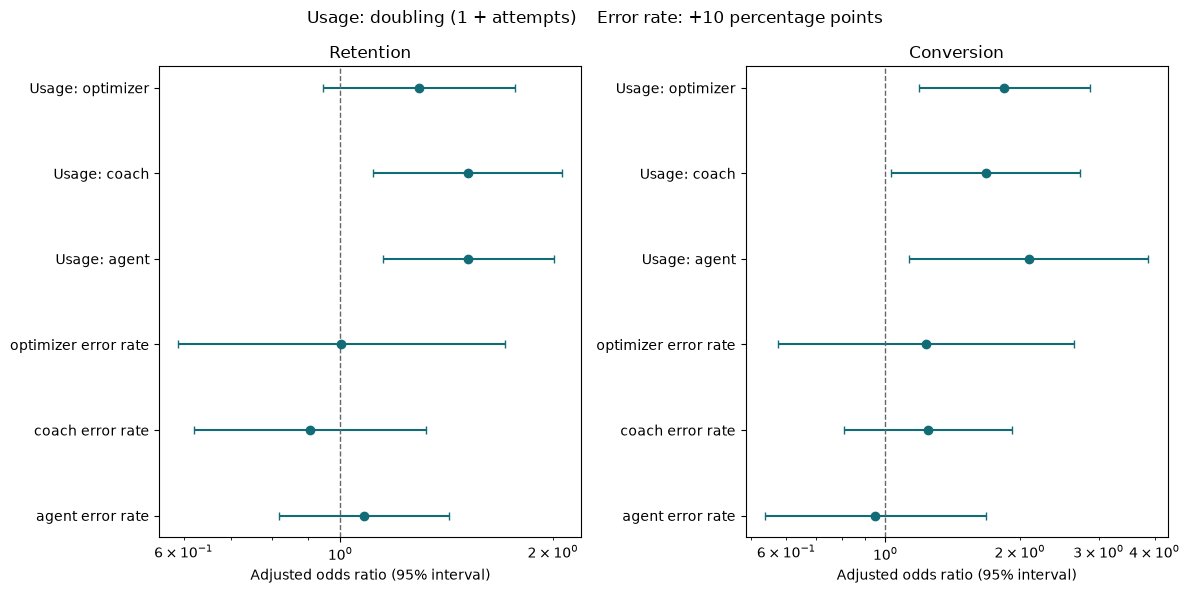

In [33]:
plotting.feature_association_intervals(
    association_figures=association_figures,
    primary_associations=primary_associations,
)

## Goal 3 — Differences between player groups

Segments use only days 0–6 and are fixed before looking at later outcomes.

**Weekend preference:** compare active weekend days / 2 with active weekdays / 5.
Each complete seven-day tenure window contains two weekend and five weekday
opportunities. Strictly larger activity frequency determines preference; ties
are a separate balanced group. This is activity preference, not acquisition day.

**Feature preference:** sum daily attempts divided by that day's plan limit,
then compare the three features. This corrects for very different usage caps.
The largest average fraction of daily allowance determines the dominant feature;
exact ties have their own label. Dominance measures relative preference, not
an absolute heavy-user threshold. A player can have low overall usage.

Group tables include player counts, event counts, rates and Wilson intervals.
Adjusted segment regressions include active days and initial plan for retention.
Small groups or model warnings limit interpretation. These comparisons are
exploratory and not independent of the earlier feature comparisons.
A revision after the initial diagnostic failure restricts adjusted group models
to categories with at least 10 players. Sparse groups remain in the tables;
this restriction is based on group size, not the direction of the association.

### Assign groups using only first-week behavior

In [34]:
model_players, conversion_players, normalized_fields = features.assign_player_segments(
    early_activity=early_activity,
    feature_map=feature_map,
    model_players=model_players,
)

### Compare all groups and fit estimable contrasts

In [35]:
segment_summary, segment_model_scope = modeling.fit_segment_comparisons(
    conversion_players=conversion_players,
    model_players=model_players,
    models=models,
)

segment_coefficients = reporting.save_segment_comparisons(
    association_checks=association_checks,
    association_tables=association_tables,
    model_players=model_players,
    models=models,
    normalized_fields=normalized_fields,
    segment_model_scope=segment_model_scope,
    segment_summary=segment_summary,
)

display(segment_summary.round(2))
display(pd.DataFrame(segment_model_scope))
display(segment_coefficients[["model", "term", "odds_ratio", "ci_low", "ci_high", "bh_q"]].round(4))

,segment,group,outcome,players,events,rate_pct,ci_low_pct,ci_high_pct
0,weekend_preference,Balanced,retention,41,28,68.29,53.02,80.44
1,weekend_preference,Weekday,retention,109,53,48.62,39.45,57.89
2,weekend_preference,Weekend,retention,150,99,66.00,58.10,73.10
3,weekend_preference,Balanced,conversion,32,6,18.75,8.89,35.31
4,weekend_preference,Weekday,conversion,88,5,5.68,2.45,12.62
5,weekend_preference,Weekend,conversion,112,22,19.64,13.34,27.95
6,feature_preference,Balanced,retention,3,3,100.00,43.85,100.00
7,feature_preference,agent,retention,105,59,56.19,46.65,65.30
8,feature_preference,coach,retention,146,88,60.27,52.17,67.85
9,feature_preference,optimizer,retention,46,30,65.22,50.77,77.32


,outcome,segment,total_players,regression_players,excluded_sparse_players,included_groups,reason
0,retention,weekend_preference,300,300,0,"Balanced, Weekday, Weekend",Diagnostic revision: sparse categories (<10 pl...
1,conversion,weekend_preference,232,232,0,"Balanced, Weekday, Weekend",Diagnostic revision: sparse categories (<10 pl...
2,retention,feature_preference,300,297,3,"agent, coach, optimizer",Diagnostic revision: sparse categories (<10 pl...
3,conversion,feature_preference,232,230,2,"agent, coach, optimizer",Diagnostic revision: sparse categories (<10 pl...


,model,term,odds_ratio,ci_low,ci_high,bh_q
65,retention_weekend_preference,"C(weekend_preference, Treatment(reference='Wee...",0.4390,0.1652,1.1669,0.2900
66,retention_weekend_preference,"C(weekend_preference, Treatment(reference='Wee...",1.5616,0.9058,2.6923,0.2900
70,conversion_weekend_preference,"C(weekend_preference, Treatment(reference='Wee...",1.5238,0.3674,6.3208,0.7035
71,conversion_weekend_preference,"C(weekend_preference, Treatment(reference='Wee...",3.3103,1.1876,9.2267,0.1767
74,retention_feature_preference,C(feature_preference)[T.coach],1.1232,0.6598,1.9123,0.7035
75,retention_feature_preference,C(feature_preference)[T.optimizer],1.1663,0.5281,2.5758,0.7035
79,conversion_feature_preference,C(feature_preference)[T.coach],0.7960,0.3605,1.7576,0.7035
80,conversion_feature_preference,C(feature_preference)[T.optimizer],0.5959,0.1247,2.8484,0.7035


## Goal 4 — Conversion timing and player journeys

First, describe all initially Free players' conversion timing from day 1 onward.
A daily risk set includes everyone not previously converted, even if inactive.
There are no Free cancellations in the source contract. A window's conditional
conversion percentage uses Free players at its start, not just eventual converters.
Sparse daily peaks are unstable, so show grouped windows as well.

For a regression consistent with the agreed landmark, use at-risk player-days
from days 7–59. Outcome = conversion that day. First-week usage predictors are
fixed at day 6, never updated with post-upgrade activity. Include log tenure day
as a parsimonious baseline timing adjustment and cluster uncertainty by player.
This assumes a smooth log-tenure pattern; the empirical hazard table remains
the direct timing answer. Repeated days do not create more than 33 conversion
events. Results describe observed conversion and do not measure intervention lift.

Journeys show feature attempts on observed days before the upgrade, alongside
the proportion active on each relative day. The upgrade day is excluded because
plan and feature counts share an end-of-day snapshot. This converter-only view
is descriptive and cannot show that a change in usage caused an upgrade.

### Observe conversion timing using Free players still at risk

In [36]:
initial_free_roster, conversion_hazard, conversion_windows = metrics.conversion_risk_sets(
    association_tables=association_tables,
    model_players=model_players,
)

display(conversion_windows.round(2))

,start_day,end_day,days_in_window,free_at_start,conversions,conditional_conversion_pct,ci_low_pct,ci_high_pct
0,1,6,6,232,0,0.00,0.00,1.63
1,7,13,7,232,11,4.74,2.67,8.29
2,14,20,7,221,5,2.26,0.97,5.19
3,21,27,7,216,2,0.93,0.25,3.31
4,28,34,7,214,5,2.34,1.00,5.35
5,35,41,7,209,5,2.39,1.03,5.48
6,42,48,7,204,5,2.45,1.05,5.61
7,49,55,7,199,0,0.00,0.00,1.89
8,56,59,4,199,0,0.00,0.00,1.89


### Prepare daily risk rows

In [37]:
risk_days = features.at_risk_player_days(conversion_players=conversion_players)

In [38]:
hazard_formula = "converted_today ~ log_tenure_day + log2_optimizer + log2_coach + log2_agent + active_days"
hazard_coefficients = models.fit("daily_conversion_hazard", risk_days, hazard_formula, cluster_column="userid")
hazard_coefficients.to_csv(association_tables / "conversion_hazard_regression.csv", index=False)
display(hazard_coefficients[["term", "odds_ratio", "ci_low", "ci_high", "p_value"]].round(4))
print("Hazard ORs refer to conditional daily conversion odds, not 53-day cumulative conversion probabilities.")

,term,odds_ratio,ci_low,ci_high,p_value
0,Intercept,0.0004,0.0000,0.0073,0.0000
1,log_tenure_day,0.4788,0.2853,0.8033,0.0053
2,log2_optimizer,1.6484,1.1929,2.2777,0.0025
3,log2_coach,1.5506,1.0013,2.4013,0.0493
4,log2_agent,1.9698,1.1220,3.4581,0.0182
5,active_days,0.5950,0.3472,1.0197,0.0589


Hazard ORs refer to conditional daily conversion odds, not 53-day cumulative conversion probabilities.


### Summarize the week before conversion

In [39]:
converters, journey_summary = metrics.preconversion_journeys(
    activity=activity,
    association_tables=association_tables,
    calendar=calendar,
    initial_free_roster=initial_free_roster,
)

display(journey_summary.round(2))

Conversion tenure among 33 converters: median 24, range 7–43 days. This conditions on converting.


,relative_day,eligible_converters,active_converters,optimizer_attempts_per_active_day,coach_attempts_per_active_day,agent_attempts_per_active_day,active_pct
0,-7,33,25,11.60,5.36,2.44,75.76
1,-6,33,26,14.00,5.38,2.42,78.79
2,-5,33,22,13.09,4.91,2.73,66.67
3,-4,33,25,12.44,5.36,2.28,75.76
4,-3,33,23,9.96,5.17,2.61,69.70
5,-2,33,28,14.71,5.29,2.14,84.85
6,-1,33,28,17.11,4.89,1.93,84.85


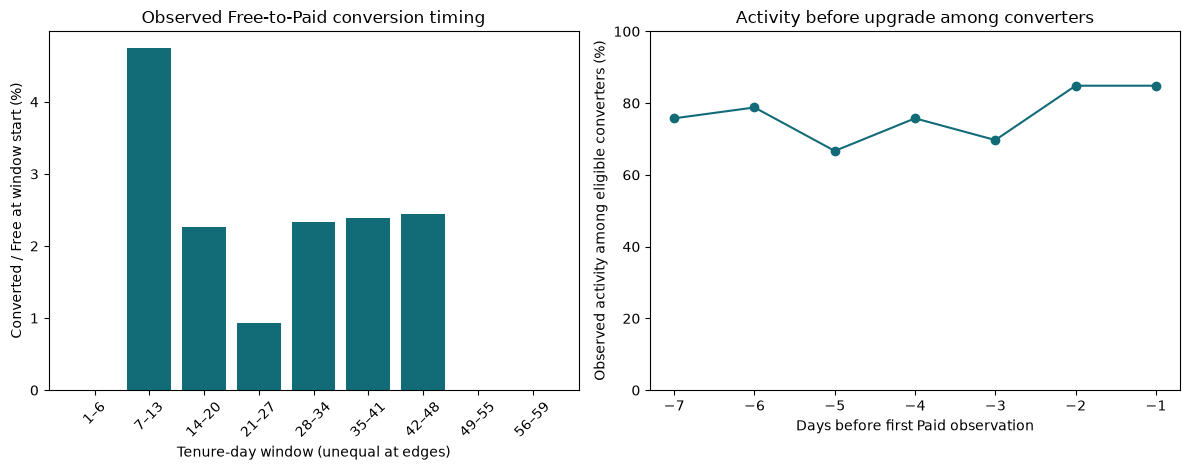

In [40]:
plotting.conversion_timing_and_journey(
    association_figures=association_figures,
    conversion_windows=conversion_windows,
    journey_summary=journey_summary,
)

## Diagnostics, sensitivity and independent verification

Compare the same feature's joint usage model with its simpler feature-specific
model and restrict retention to initially Free players. For the daily hazard,
add quadratic log tenure as a prespecified functional-form sensitivity.
Inference remains exploratory. The independent route below rebuilds all
first-week totals, retention outcomes, and later-conversion counts from the CSV,
checks rank correlations, and refits the two main usage models with SciPy's
Bernoulli likelihood rather than statsmodels' fitting routine.

In [41]:
risk_days["log_tenure_centered"] = risk_days.log_tenure_day - risk_days.log_tenure_day.mean()
risk_days["log_tenure_squared"] = risk_days.log_tenure_centered ** 2
models.fit("daily_conversion_hazard_quadratic_time", risk_days,
    hazard_formula.replace("log_tenure_day", "log_tenure_centered") + " + log_tenure_squared", cluster_column="userid")

,model,term,coefficient,standard_error,odds_ratio,ci_low,ci_high,p_value,interpretation_ready
0,daily_conversion_hazard_quadratic_time,Intercept,-10.065820,1.010834,0.000043,0.000006,0.000308,2.328527e-23,True
1,daily_conversion_hazard_quadratic_time,log_tenure_centered,-0.972690,0.353631,0.378065,0.189040,0.756097,5.949007e-03,True
2,daily_conversion_hazard_quadratic_time,log2_optimizer,0.498086,0.164406,1.645569,1.192268,2.271217,2.448632e-03,True
3,daily_conversion_hazard_quadratic_time,log2_coach,0.436833,0.222616,1.547797,1.000514,2.394446,4.973100e-02,True
4,daily_conversion_hazard_quadratic_time,log2_agent,0.678104,0.287053,1.970138,1.122424,3.458091,1.816212e-02,True
5,daily_conversion_hazard_quadratic_time,active_days,-0.517628,0.274025,0.595932,0.348295,1.019641,5.889395e-02,True
6,daily_conversion_hazard_quadratic_time,log_tenure_squared,-0.363731,0.385674,0.695078,0.326398,1.480200,3.456280e-01,True


### Review diagnostics and specification sensitivity

In [42]:
all_coefficients, diagnostics = reporting.export_model_diagnostics(
    association_checks=association_checks,
    association_tables=association_tables,
    models=models,
)

sensitivity_summary, hazard_sensitivity = reporting.export_sensitivities(
    all_coefficients=all_coefficients,
    association_tables=association_tables,
    feature_map=feature_map,
)

display(diagnostics[["model", "players", "events", "parameters", "converged", "max_vif", "warnings"]].round(2))
display(sensitivity_summary.round(3))

,model,players,events,parameters,converged,max_vif,warnings
0,retention_usage,300,180,6,True,5.28,
1,conversion_usage,232,33,5,True,5.25,
2,retention_optimizer_single_usage,300,180,4,True,2.16,
3,retention_coach_single_usage,300,180,4,True,2.01,
4,retention_agent_single_usage,300,180,4,True,1.74,
5,retention_usage_initial_free_only,232,136,5,True,5.25,
6,conversion_optimizer_single_usage,232,33,3,True,2.14,
7,conversion_coach_single_usage,232,33,3,True,2.02,
8,conversion_agent_single_usage,232,33,3,True,1.70,
9,retention_optimizer_errors,300,180,5,True,2.16,


,outcome,feature,specification,odds_ratio,ci_low,ci_high
0,retention,optimizer,retention_usage,1.291,0.945,1.765
1,retention,optimizer,retention_optimizer_single_usage,1.103,0.822,1.480
2,retention,optimizer,retention_usage_initial_free_only,1.173,0.827,1.665
3,retention,coach,retention_usage,1.514,1.112,2.060
4,retention,coach,retention_coach_single_usage,1.373,1.034,1.824
5,retention,coach,retention_usage_initial_free_only,1.606,1.126,2.291
6,retention,agent,retention_usage,1.518,1.149,2.006
7,retention,agent,retention_agent_single_usage,1.376,1.057,1.790
8,retention,agent,retention_usage_initial_free_only,1.651,1.208,2.257
9,conversion,optimizer,conversion_usage,1.844,1.187,2.865


### Independently verify features, outcomes and conversion risk sets

In [43]:
source_later_converters = validation.verify_features_and_risk_sets(
    conversion_hazard=conversion_hazard,
    conversion_players=conversion_players,
    data_path=data_path,
    feature_map=feature_map,
    model_players=model_players,
)

validation.verify_rank_correlations(correlations=correlations, samples=samples)

### Independently refit the main likelihoods

In [44]:
validation.verify_regression_optimizers(association_checks=association_checks, models=models)

validation.verify_final_analysis_population(
    association_folder=association_folder,
    conversion_windows=conversion_windows,
    converters=converters,
    data_path=data_path,
    early_features=early_features,
    feature_audit=feature_audit,
    model_players=model_players,
    risk_days=risk_days,
    source_later_converters=source_later_converters,
    source_sha256=source_sha256,
)

Independent source totals/outcomes, all hazard risk sets, rank correlations, both main regression optimizers, and source hash matched.


## Findings and implications

The following summary is generated from the executed result tables. Raw
correlations and adjusted models answer different questions. Highlighted
associations are hypotheses for further research, not product-effect estimates.

### Read and save the checked findings

In [45]:
findings = reporting.write_association_findings(
    association_folder=association_folder,
    conversion_players=conversion_players,
    conversion_windows=conversion_windows,
    converters=converters,
    correlations=correlations,
    model_players=model_players,
    primary_associations=primary_associations,
    segment_summary=segment_summary,
)

reporting.save_association_record(
    analysis_plan=analysis_plan,
    association_checks=association_checks,
    case_folder=case_folder,
    conversion_players=conversion_players,
    diagnostics=diagnostics,
    model_players=model_players,
    models=models,
    source_sha256=source_sha256,
)

display(Markdown(findings))

# Additional-analysis findings

## Scope

Predictors: days0–6. Retention: any activity days28–34. Conversion: days7–59 among initially Free players still Free after day6.
Retention: 180/300. Conversion: 33/232. No first-week conversions were observed.

## Unadjusted correlations

- retention: coach attempts, Spearman rho=0.312, permutation BH q=0.001, n=300.
- retention: agent attempts, Spearman rho=0.307, permutation BH q=0.001, n=300.
- retention: optimizer attempts, Spearman rho=0.258, permutation BH q=0.001, n=300.
- conversion: agent attempts, Spearman rho=0.214, permutation BH q=0.004, n=232.
- conversion: optimizer attempts, Spearman rho=0.187, permutation BH q=0.008, n=232.
- conversion: optimizer errors, Spearman rho=0.182, permutation BH q=0.014, n=232.

## Adjusted feature associations

- retention_usage, log2_optimizer: OR 1.29 (95% interval 0.95–1.76), BH q=0.217.
- retention_usage, log2_coach: OR 1.51 (95% interval 1.11–2.06), BH q=0.033.
- retention_usage, log2_agent: OR 1.52 (95% interval 1.15–2.01), BH q=0.033.
- conversion_usage, log2_optimizer: OR 1.84 (95% interval 1.19–2.86), BH q=0.033.
- conversion_usage, log2_coach: OR 1.67 (95% interval 1.03–2.73), BH q=0.092.
- conversion_usage, log2_agent: OR 2.09 (95% interval 1.13–3.88), BH q=0.058.
- retention_optimizer_errors, optimizer_error_10pp: OR 1.00 (95% interval 0.59–1.71), BH q=0.989.
- retention_coach_errors, coach_error_10pp: OR 0.91 (95% interval 0.62–1.32), BH q=0.729.
- retention_agent_errors, agent_error_10pp: OR 1.08 (95% interval 0.82–1.42), BH q=0.729.
- conversion_optimizer_errors, optimizer_error_10pp: OR 1.23 (95% interval 0.58–2.65), BH q=0.729.
- conversion_coach_errors, coach_error_10pp: OR 1.24 (95% interval 0.81–1.92), BH q=0.558.
- conversion_agent_errors, agent_error_10pp: OR 0.95 (95% interval 0.54–1.68), BH q=0.935.

3 of 12 primary feature slopes have BH q<0.05. Intervals are pointwise, not multiplicity-adjusted. Absence of a clear association is not proof of no relationship.
Usage ORs are per doubling of 1+attempts. Error-rate ORs are per 10 percentage points and use feature-specific volume adjustment.
Coach and Agent use have the clearest adjusted retention associations; Optimizer use has the clearest adjusted conversion association. All six adjusted error-rate intervals include 1. Raw positive error-count correlations can reflect usage volume, not a beneficial effect of errors.
Simpler usage fits and initially-Free-only retention estimates are saved in tables/usage_sensitivity.csv. Collinearity among usage and engagement limits attribution to one feature; the model changes should be read as sensitivity, not independent replications.

## Segments

- weekend_preference=Balanced, retention: 28/41 (68.3%; Wilson interval 53.0–80.4%).
- weekend_preference=Weekday, retention: 53/109 (48.6%; Wilson interval 39.4–57.9%).
- weekend_preference=Weekend, retention: 99/150 (66.0%; Wilson interval 58.1–73.1%).
- weekend_preference=Balanced, conversion: 6/32 (18.8%; Wilson interval 8.9–35.3%).
- weekend_preference=Weekday, conversion: 5/88 (5.7%; Wilson interval 2.5–12.6%).
- weekend_preference=Weekend, conversion: 22/112 (19.6%; Wilson interval 13.3–28.0%).
- feature_preference=Balanced, retention: 3/3 (100.0%; Wilson interval 43.9–100.0%).
- feature_preference=agent, retention: 59/105 (56.2%; Wilson interval 46.6–65.3%).
- feature_preference=coach, retention: 88/146 (60.3%; Wilson interval 52.2–67.8%).
- feature_preference=optimizer, retention: 30/46 (65.2%; Wilson interval 50.8–77.3%).
- feature_preference=Balanced, conversion: 1/2 (50.0%; Wilson interval 9.5–90.5%).
- feature_preference=agent, conversion: 14/89 (15.7%; Wilson interval 9.6–24.7%).
- feature_preference=coach, conversion: 16/122 (13.1%; Wilson interval 8.2–20.2%).
- feature_preference=optimizer, conversion: 2/19 (10.5%; Wilson interval 2.9–31.4%).

Weekend preference is associated with higher unadjusted retention and conversion than weekday preference. Adjusted direct comparisons and exploratory BH q-values are in tables/segment_regressions.csv. Feature preference groups have overlapping intervals and do not support confident ranking.
Diagnostic revision: a 3-player balanced feature group caused non-finite standard errors in the original subgroup model. Categories with fewer than 10 players are therefore descriptive only, excluding 3 retention players and 2 conversion players from adjusted feature-preference models; other analyses retain them. See checks/segment_regression_scope.csv. No source data was changed.

## Conversion timing and journeys

The largest observed grouped conditional conversion proportion is days 7–13: 11/232 (4.7%). Unequal edge-window lengths and sparse counts limit peak comparisons.
Among the 33 converters, median upgrade tenure is 24 days (range 7–43). This excludes nonconverters by definition.
The pre-upgrade journey conditions on eventual conversion and excludes the upgrade day. Activity gaps and per-active-day feature means must be interpreted together.

## Limits and next decisions

Synthetic observational data supports association, not causal effects or real-customer forecasts. Starting plan, usage caps, general engagement, cohort timing and unmeasured intent can confound relationships. Models adjust selected measured variables only.
Only 33 conversion events support limited precision. Review all diagnostics, collinearity, simpler-model and baseline-timing sensitivities. Correlation and subgroup exploration involve multiple comparisons.
Use feature and segment signals to specify a prospective randomized onboarding or reliability experiment, not to claim that increasing feature use causes retention. Confirm results on real cohorts, protect player-level evaluation splits for prediction, and improve event-time/billing telemetry before operational targeting.

## Reproduction and checks

Run the complete notebook in the project kernel or create_notebook.py in the activated environment. All source-level feature/outcome/hazard checks and independent main-model coefficient checks passed. Source input hash is unchanged. See checks/ and tables/ for full evidence.